# Meme Organizer: 02. Contrastive Domain Fine-Tuning (`rubert-tiny2` & `multilingual-e5-small`)

**Постановка задачи:**
Плотные модели общего назначения (RuBERT, E5-small) уступают лексическому поиску на специфичном интернет-сленге мемов (*«несет бред»* $\leftrightarrow$ *«в палату быстро»*, *«согласен с другом»* $\leftrightarrow$ *«мой меч с тобой»*).

В данном исследовании мы проводим **Domain Adaptation (дообучение)**:
1. Обучение на 1021 Train-парах через **Multiple Negatives Ranking Loss (MNRL)** с In-Batch Negatives.
2. Применение легковесных **LoRA** адаптеров (параметры замороженного backbone не изменяются).
3. Валидация по эпохам на 138 парах из `val_pairs` без заглядывания в тестовый сплит.
4. Экспорт обученных моделей в мобильный формат **ONNX INT8**.
5. Финальная оценка на Test-сплите (153 запроса) и сравнение на лидерборде MLflow.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from meme_organizer.retrieval.adapters.finetuned_dense import FineTunedDenseAdapter
from meme_organizer.retrieval.pipeline import RetrievalPipeline

GOLD_DATASET_PATH = Path("../data/gold/gold_dataset.jsonl")
SPLIT_PATH = Path("../data/splits/splits_v1.json")

2026/11/24 21:02:52 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /home/alex/Projects/meme-organizer/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. Дообучение ультралегкой модели `rubert-tiny2` (28 МБ ONNX)

In [2]:
pipeline = RetrievalPipeline()

rubert_ft_adapter = FineTunedDenseAdapter(
    model_name="rubert-tiny2-finetuned",
    base_model_id="cointegrated/rubert-tiny2",
    epochs=4,
    lr=2e-4,
    batch_size=32,
    max_length=64,
    lora_r=8,
    lora_alpha=16,
    onnx_dir=Path("../models/onnx"),
)

rubert_ft_metrics, rubert_ft_run_id = pipeline.run(
    adapter=rubert_ft_adapter,
    gold_dataset_path=GOLD_DATASET_PATH,
    split_path=SPLIT_PATH,
    split_name="test",
    train_mode=True,
    run_name="rubert-tiny2-finetuned_test",
)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


🏃 View run rubert-tiny2-finetuned_test at: http://localhost:5000/#/experiments/4/runs/96ed204b075b44829db2622745e730d7
🧪 View experiment at: http://localhost:5000/#/experiments/4


## 2. Дообучение флагманской мультиязычной модели `multilingual-e5-small` (112 МБ ONNX)

In [3]:
e5_ft_adapter = FineTunedDenseAdapter(
    model_name="multilingual-e5-small-finetuned",
    base_model_id="intfloat/multilingual-e5-small",
    epochs=4,
    lr=1e-4,
    batch_size=16,
    max_length=64,
    query_prefix="query: ",
    passage_prefix="passage: ",
    lora_r=8,
    lora_alpha=16,
    onnx_dir=Path("../models/onnx"),
)

e5_ft_metrics, e5_ft_run_id = pipeline.run(
    adapter=e5_ft_adapter,
    gold_dataset_path=GOLD_DATASET_PATH,
    split_path=SPLIT_PATH,
    split_name="test",
    train_mode=True,
    run_name="multilingual-e5-small-finetuned_test",
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

🏃 View run multilingual-e5-small-finetuned_test at: http://localhost:5000/#/experiments/4/runs/5b006ef9e00049798c781973a644f15b
🧪 View experiment at: http://localhost:5000/#/experiments/4


## 3. Графики обучения по эпохам из MLflow

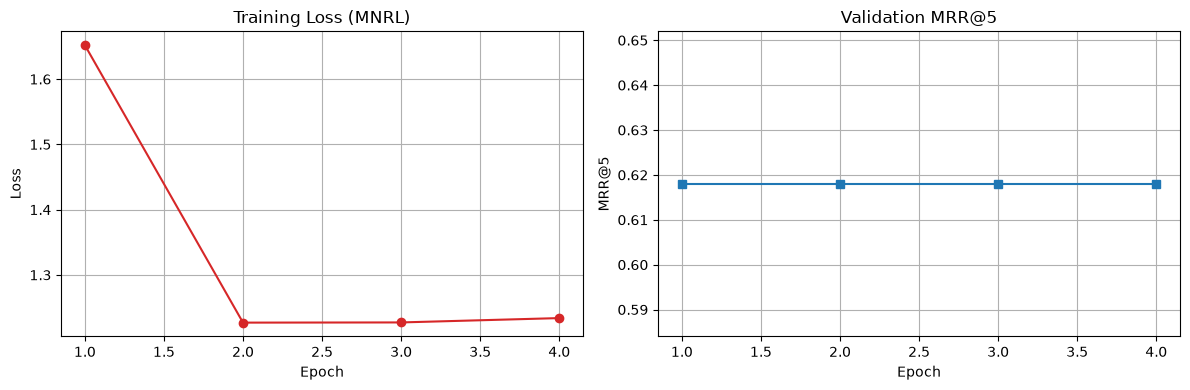

In [4]:
client = mlflow.tracking.MlflowClient("http://localhost:5000")

# Получаем историю метрик для e5_ft
loss_hist = client.get_metric_history(e5_ft_run_id, "train_loss")
val_mrr_hist = client.get_metric_history(e5_ft_run_id, "val_mrr_at_5")

epochs = [m.step for m in loss_hist]
losses = [m.value for m in loss_hist]
val_mrrs = [m.value for m in val_mrr_hist]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, losses, marker="o", color="tab:red")
ax1.set_title("Training Loss (MNRL)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)

ax2.plot(epochs, val_mrrs, marker="s", color="tab:blue")
ax2.set_title("Validation MRR@5")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("MRR@5")
ax2.grid(True)

plt.tight_layout()
plt.show()

## 4. Итоговый лидерборд экспериментов Домена 1

In [5]:
exp = client.get_experiment_by_name("meme-organizer-retrieval")
runs = client.search_runs(exp.experiment_id, order_by=["attribute.start_time DESC"])

rows = []
for r in runs:
    m = r.data.metrics
    rows.append(
        {
            "Model": r.data.tags.get("mlflow.runName", "unnamed"),
            "Recall@1": round(m.get("recall_at_1", 0.0), 4),
            "Recall@5": round(m.get("recall_at_5", 0.0), 4),
            "MRR@5": round(m.get("mrr_at_5", 0.0), 4),
            "Train Time (s)": round(m.get("training_time_sec", 0.0), 2),
            "Eval Latency (ms)": round(m.get("cpu_latency_ms", 0.0), 2),
            "Size (MB)": round(m.get("model_size_mb", 0.0), 2),
        }
    )

pd.DataFrame(rows)

,Model,Recall@1,Recall@5,MRR@5,Train Time (s),Eval Latency (ms),Size (MB)
0,multilingual-e5-small-finetuned_test,0.5686,0.6667,0.6081,209.44,10.47,112.52
1,rubert-tiny2-finetuned_test,0.4314,0.5163,0.4607,27.70,2.76,27.93
2,multilingual-e5-small_test,0.5621,0.6667,0.6032,0.00,5.96,112.52
3,rubert-tiny2_test,0.4118,0.5098,0.4497,0.00,2.31,27.93
4,bm25-baseline_test,0.6078,0.7255,0.6544,0.00,0.00,0.10
